# Upwinding, CFL, dissipation and dispersion

**Source mapping:** Vercauteren, Simulation and Modelling 2 (9 July 2025), §5.3.4, pp. 45–48.

Independent study companion; explanations and experiments are newly written. Read in the README order.

## Model and reasoning

For positive velocity, forward Euler with backward space differences gives c_new=c-C(c-roll(c,1)), C=v*dt/dx. Stability requires 0<=C<=1. For negative velocity use forward space differences instead. Forward time with centred space is unstable for pure advection: |G|²=1+C² sin²(theta).

Upwind amplification G=1-C(1-exp(-i theta)) has modulus below one for most modes: numerical diffusion smooths the solution. Its phase need not equal -C theta, producing dispersion. CFL is a necessary domain-of-dependence condition for many explicit methods, not a universal sufficient accuracy or stability guarantee.

## Reproducible experiment

Predict the plot before running. All parameters below are illustrative, not measured environmental data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})
rng = np.random.default_rng(42)

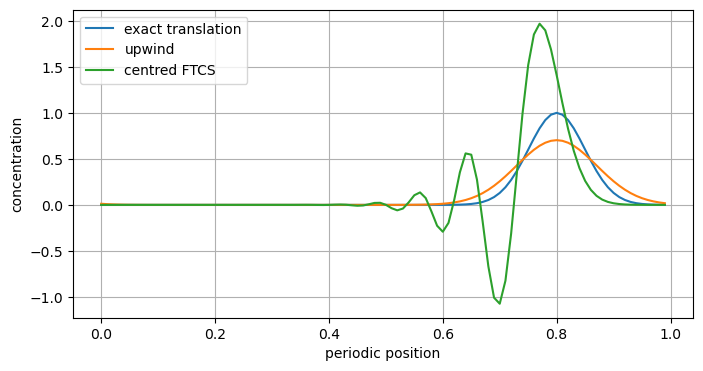

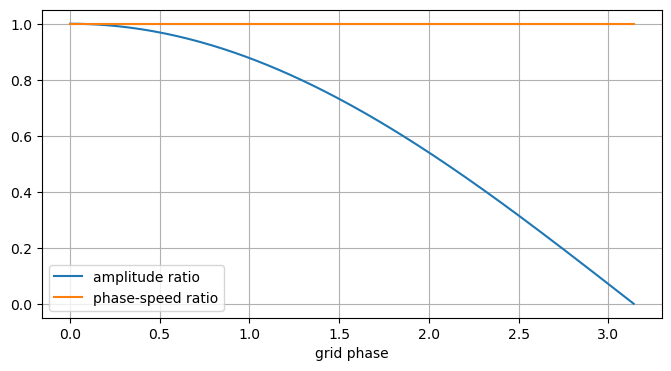

In [2]:
N=100;x=np.arange(N)/N;dx=1/N;v=1.;C=.5;dt=C*dx/v;steps=100
c0=np.exp(-((x-.3)/.07)**2);up=c0.copy();central=c0.copy()
for _ in range(steps):
 up-=C*(up-np.roll(up,1));central-=C/2*(np.roll(central,-1)-np.roll(central,1))
exact=np.exp(-((((x-v*steps*dt-.3+.5)%1)-.5)/.07)**2)
plt.plot(x,exact,label="exact translation");plt.plot(x,up,label="upwind");plt.plot(x,central,label="centred FTCS");plt.xlabel("periodic position");plt.ylabel("concentration");plt.legend();plt.show()
assert abs(up.sum()-c0.sum())<1e-10
assert up.min()>-1e-12
th=np.linspace(.001,np.pi-.001,300);G=1-C*(1-np.exp(-1j*th))
plt.plot(th,abs(G),label="amplitude ratio");plt.plot(th,-np.angle(G)/(C*th),label="phase-speed ratio");plt.xlabel("grid phase");plt.legend();plt.show()

## Read the result

Mass conservation does not guarantee shape preservation. At C=1 the positive-velocity upwind update shifts samples exactly one cell; for smaller C it introduces smoothing.

## Your turn

Repeat with C=0.25 and C=0.75 at a common final time. Implement negative velocity and verify the direction of travel.

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.